## Importing Libraries

In [ ]:
from langchain_ollama import ChatOllama, OllamaEmbeddings
from langchain_qdrant import FastEmbedSparse, QdrantVectorStore, RetrievalMode
from qdrant_client import QdrantClient

from typing import TypedDict, List
from langgraph.graph import StateGraph, START, END
from langchain_core.documents import Document
from IPython.display import Image, display, Markdown

/Users/animesh/anaconda3/envs/agentic-rag/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Loading Models and Vectordatabase

In [2]:
embeddings = OllamaEmbeddings(
    model="bge-m3"
)
llm = ChatOllama(
    model="qwen3.5:latest",
    temperature=0
)

sparse_embeddings = FastEmbedSparse(model_name="Qdrant/bm25")


# Create a Qdrant client for local storage
client = QdrantClient(path="./langchain_qdrant")

vector_store = QdrantVectorStore(
    client=client,
    collection_name="pdf_collection",
    embedding=embeddings,
    sparse_embedding=sparse_embeddings,
    retrieval_mode=RetrievalMode.HYBRID,
    vector_name="dense",
    sparse_vector_name="sparse",
)
retriever = vector_store.as_retriever(search_kwargs={"k": 5})

### 1. Creating LangGraph States

In [3]:
class RAGState(TypedDict):
    query: str
    documents: List[Document]
    answer: str

### 2. Retrieve Node

In [4]:
def retrieve_node(state: RAGState):

    query = state["query"]
    documents = retriever.invoke(query)

    return {
        "documents": documents
    }

### 3. Answer Generation Node

In [5]:
def answer_generation_node(state: RAGState):

    query = state["query"]
    documents = state["documents"]

    retrieved_details = []
    for i in documents:
            retrieved_details.append(f"Content: {i.page_content}\nMetadata: {i.metadata}")

    context = "\n\n".join(retrieved_details)

    system_prompt = f"""
You are a helpful RAG assistant.
Answer the user's question using ONLY the provided context.

If the answer cannot be found in the context,
say that you don't have enough information.

Context:
----------------
{context}
----------------
"""
    ##Building messages
    system_message = {
                "role": "system",
                "content": system_prompt
            }
    user_message = {
                "role": "user",
                "content": query
            }

    response = llm.invoke([system_message, user_message])

    return {
        "answer": response.content
    }

### 4. Building Graph

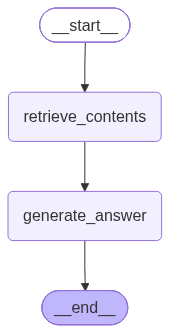

In [11]:
graph_builder = StateGraph(RAGState)

# Adding nodes
graph_builder.add_node(
    "retrieve_contents",
    retrieve_node
)

graph_builder.add_node(
    "generate_answer",
    answer_generation_node
)


# Define edges
graph_builder.add_edge(
    START,
    "retrieve_contents"
)

graph_builder.add_edge(
    "retrieve_contents",
    "generate_answer"
)

graph_builder.add_edge(
    "generate_answer",
    END
)

rag_graph = graph_builder.compile()
display(Image(rag_graph.get_graph().draw_mermaid_png()))

### 5. Querying Graph

In [ ]:
# ---------------------------------------------------------
# Ask User Query using stream
# ---------------------------------------------------------

query = "Explain table-1"

for event in rag_graph.stream({"query": query, "documents": [], "answer": ""}, stream_mode="updates"):
    for node_name, node_output in event.items():
        print("Node:", node_name)
        print("Output:", node_output)

Node: retrieve_contents
Output: {'documents': [Document(metadata={'chunk_id': 'table_3_rows_1_2', 'type': 'table', 'page_number': 8, 'rows_range': '1-2', 'total_rows': 2, 'columns': ['Task', 'Accuracy'], '_id': 'cbdd266257fd4457be4ae77737e17f16', '_collection_name': 'pdf_collection'}, page_content='### Table 3 (Page 8)\n\n| Task            |   Accuracy |\n|:----------------|-----------:|\n| Image retrieval |     0.6566 |\n| Table retrieval |     0.4838 |'), Document(metadata={'chunk_id': 'visual_1', 'type': 'chart_or_figure', 'page_number': 3, 'image_path': 'extracted_visuals/chart_1.png', '_id': 'ff09defcb8434c09b5d19a02a6fa58e9', '_collection_name': 'pdf_collection'}, page_content='### Visual Data / Chart\nBased on the provided figure and surrounding text, here is the analysis of the PIER-QA system architecture.\n\n### **Figure Transcription**\n\n| Process Stage | Input / Component | Operation / Action | Output / Storage |\n| :--- | :--- | :--- | :--- |\n| **Document Preprocessing** 

In [10]:
Markdown(node_output['answer'])

Based on the provided context, here is an explanation of **Table 1 (Page 7)**:

## Table 1 Overview

Table 1 presents a performance comparison between two systems: **Baseline** and **PIER-QA**, evaluated using two different LLM agents: **GPT-3.5-turbo** and **GPT-4o**.

### Performance Metrics Measured

| Metric | Description |
|--------|-------------|
| **Similarity** | Overall similarity score between query and retrieved information |
| **Accuracy @0.85** | Accuracy when the similarity threshold is 0.85 |
| **Accuracy @0.9** | Accuracy when the similarity threshold is 0.9 |
| **Accuracy @0.95** | Accuracy when the similarity threshold is 0.95 |

### Key Results

| System | LLM Agent | Similarity | Accuracy @0.85 | Accuracy @0.9 | Accuracy @0.95 |
|--------|-----------|------------|----------------|---------------|----------------|
| Baseline | GPT-3.5-turbo | 0.8639 | 0.5889 | 0.3667 | 0.06 |
| Baseline | GPT-4o | 0.8647 | 0.6444 | 0.4 | 0.1111 |
| PIER-QA | GPT-3.5-turbo | 0.8666 | 0.764 | 0.3708 | 0.1124 |
| PIER-QA | GPT-4o | 0.8837 | 0.7191 | 0.4944 | 0.191 |

### Key Findings

According to the accompanying text (Section 5.1 Comparison with Baseline):

1. **PIER-QA outperforms the baseline** across all similarity thresholds (0.85, 0.9, and 0.95) with both LLM agents.

2. **Highest performance**: PIER-QA with GPT-4o achieved the best results:
   - Similarity: 0.8837
   - Accuracy @0.95: 0.191 (highest among all configurations)

3. **Improvement attributed to**: Enhanced preprocessing steps including header/footer removal, markdown conversion, and effective retrieval and integration of images, diagrams, and tables.

4. **Particularly notable at higher thresholds**: The accuracy improvements are more pronounced at higher similarity thresholds (0.95), demonstrating PIER-QA's capability to handle complex PDF-based questions comprehensively.

In [17]:
# ---------------------------------------------------------
# Ask Query using invoke
# ---------------------------------------------------------

query = "Explain table-1"

result = rag_graph.invoke({
    "query": query,
    "documents": [],
    "answer": ""
})

Markdown(result["answer"])

Based on the provided context, here is an explanation of **Table 1 (Page 7)**:

## Table 1 Overview

Table 1 presents a performance comparison between two systems: **Baseline** and **PIER-QA**, evaluated using two different LLM agents: **GPT-3.5-turbo** and **GPT-4o**.

### Performance Metrics Measured

| Metric | Description |
|--------|-------------|
| **Similarity** | Overall similarity score between query and retrieved information |
| **Accuracy @0.85** | Accuracy when the similarity threshold is 0.85 |
| **Accuracy @0.9** | Accuracy when the similarity threshold is 0.9 |
| **Accuracy @0.95** | Accuracy when the similarity threshold is 0.95 |

### Key Results

| System | LLM Agent | Similarity | Accuracy @0.85 | Accuracy @0.9 | Accuracy @0.95 |
|--------|-----------|------------|----------------|---------------|----------------|
| Baseline | GPT-3.5-turbo | 0.8639 | 0.5889 | 0.3667 | 0.06 |
| Baseline | GPT-4o | 0.8647 | 0.6444 | 0.4 | 0.1111 |
| PIER-QA | GPT-3.5-turbo | 0.8666 | 0.764 | 0.3708 | 0.1124 |
| PIER-QA | GPT-4o | 0.8837 | 0.7191 | 0.4944 | 0.191 |

### Key Findings

According to the accompanying text (Section 5.1 Comparison with Baseline):

1. **PIER-QA outperforms the baseline** across all similarity thresholds (0.85, 0.9, and 0.95) with both LLM agents.

2. **Highest performance**: PIER-QA with GPT-4o achieved the best results:
   - Similarity: 0.8837
   - Accuracy @0.95: 0.191 (highest among all configurations)

3. **Improvement attributed to**: Enhanced preprocessing steps including header/footer removal, markdown conversion, and effective retrieval and integration of images, diagrams, and tables.

4. **Particularly notable at higher thresholds**: The accuracy improvements are more pronounced at higher similarity thresholds (0.95), demonstrating PIER-QA's capability to handle complex PDF-based questions comprehensively.